# Postal Address City Extraction

This notebook crops the recipient label, reads it with Tesseract, and extracts only the most likely city using pattern and fuzzy matching. No LLM, CSV, or database is used.

In [41]:
%pip install opencv-python pillow matplotlib pytesseract pandas numpy rfdetr

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [42]:
from pathlib import Path
import re
from difflib import SequenceMatcher
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
from PIL import Image

TESSERACT_PATH = Path(r'C:\Program Files\Tesseract-OCR\tesseract.exe')
if TESSERACT_PATH.exists():
    pytesseract.pytesseract.tesseract_cmd = str(TESSERACT_PATH)
LANGUAGES = pytesseract.get_languages(config='')
OCR_LANG = 'eng+sin' if 'sin' in LANGUAGES else 'eng'
print('OCR language:', OCR_LANG)

OCR language: eng+sin


In [43]:
CITY_CANDIDATES = [
    'Colombo', 'Dehiwala-Mount Lavinia', 'Galkissa', 'Moratuwa', 'Negombo',
    'Pita Kotte', 'Sri Jayewardenepura Kotte', 'Katunayaka', 'Battaramulla South',
    'Maharagama', 'Kotikawatta', 'Kolonnawa', 'Hendala', 'Welisara', 'Kalutara',
    'Homagama', 'Beruwala', 'Panadura', 'Mulleriyawa', 'Kandana', 'Ja Ela',
    'Wattala', 'Peliyagoda', 'Kelaniya', 'Hanwella Ihala', 'Gampaha',
    'Horana South', 'Minuwangoda', 'Horawala Junction'
]

In [44]:
def show_image(image, title='', cmap=None, figsize=(12, 7)):
    display_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) if len(image.shape) == 3 else image
    plt.figure(figsize=figsize)
    plt.imshow(display_image, cmap=cmap)
    plt.title(title)
    plt.axis('off')
    plt.show()

def preprocess_image(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if len(image.shape) == 3 else image.copy()
    gray = cv2.bilateralFilter(gray, 7, 50, 50)
    return cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)

def enhance_for_ocr(image, scale=3):
    enlarged = cv2.resize(image, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
    return cv2.cvtColor(cv2.detailEnhance(cv2.cvtColor(enlarged, cv2.COLOR_GRAY2BGR), sigma_s=10, sigma_r=0.15), cv2.COLOR_BGR2GRAY)

def crop_relative(image, x1=0.34, y1=0.36, x2=0.69, y2=0.66):
    h, w = image.shape[:2]
    return image[int(h*y1):int(h*y2), int(w*x1):int(w*x2)]

[2026-10-22 11:49:54] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-22 11:49:54] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


[2026-10-22 11:49:54] [WARNING] rf-detr - Checkpoint has 1 classes but model is configured for 90. Using checkpoint class count (1). Pass num_classes=1 to suppress this warning.
[2026-10-22 11:49:54] [WARNING] rf-detr - load_pretrain_weights: args.num_queries absent; inferred ckpt_num_queries=300 from tensor rows 3900 ÷ ckpt_group_detr=13.
[2026-10-22 11:49:55] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


Detected address block: (np.int64(415), np.int64(769), np.int64(680), np.int64(1345)) | confidence: 0.510 | threshold used: 0.33


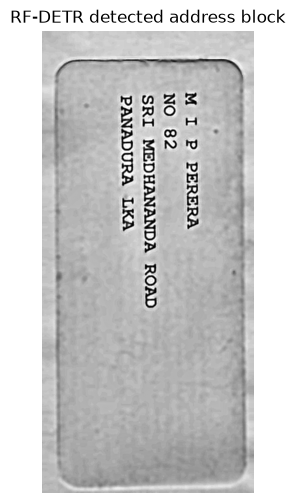

In [45]:
from rfdetr import RFDETRSmall

IMAGE_PATH = Path('./test/3.jpeg')
WEIGHTS_PATH = Path(r'C:\Users\User\Desktop\address_extraction\weights (1).pt')
CONFIDENCE_THRESHOLD = 0.33
image = cv2.imread(str(IMAGE_PATH))
if image is None:
    raise FileNotFoundError(IMAGE_PATH)
if not WEIGHTS_PATH.is_file():
    raise FileNotFoundError(f'Weight file not found: {WEIGHTS_PATH}')
detector = RFDETRSmall(pretrain_weights=str(WEIGHTS_PATH))
rgb_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
detections = detector.predict(rgb_image, threshold=CONFIDENCE_THRESHOLD)
boxes = np.asarray(detections.xyxy)
scores = np.asarray(getattr(detections, 'confidence', getattr(detections, 'scores', np.ones(len(boxes)))))
used_threshold = CONFIDENCE_THRESHOLD
if len(boxes) == 0:
    print('No detection at 0.33; retrying at 0.10 because this model has limited recall.')
    used_threshold = 0.10
    detections = detector.predict(rgb_image, threshold=used_threshold)
    boxes = np.asarray(detections.xyxy)
    scores = np.asarray(getattr(detections, 'confidence', getattr(detections, 'scores', np.ones(len(boxes)))))
if len(boxes) == 0:
    raise RuntimeError('No address block detected even at fallback threshold 0.10. Check the model classes or image framing.')
best_index = int(np.argmax(scores))
x1, y1, x2, y2 = boxes[best_index].astype(int)
h, w = image.shape[:2]
x1, y1, x2, y2 = max(0,x1), max(0,y1), min(w,x2), min(h,y2)
address_region = image[y1:y2, x1:x2]
processed = preprocess_image(address_region)
address_crop = enhance_for_ocr(processed)
print(f'Detected address block: {(x1, y1, x2, y2)} | confidence: {scores[best_index]:.3f} | threshold used: {used_threshold}')
show_image(address_crop, 'RF-DETR detected address block', cmap='gray', figsize=(12, 6))

In [46]:
def read_all_orientations(crop):
    results = {}
    pil_crop = Image.fromarray(crop)
    for angle in (0, 90, 180, 270):
        rotated = pil_crop.rotate(angle, expand=True)
        text = pytesseract.image_to_string(rotated, lang=OCR_LANG, config='--psm 6')
        results[angle] = text
        print(f'\nROTATION: {angle} degrees')
        print('-' * 45)
        print(text.strip() or '[no text detected]')
    return results

rotation_results = read_all_orientations(address_crop)


ROTATION: 0 degrees
---------------------------------------------
(232 ෆිනත
(3 0 (කූ (ඹු
hOB AoA
ae,
SB 8
>
! ක්‌
_්‌

ROTATION: 90 degrees
---------------------------------------------
M I P PERERA

NO 82

SRI MEDHANANDA ROAD
PANADURA LKA

ROTATION: 180 degrees
---------------------------------------------
ය
। ෆ්‌ $
Bs
ඝි
: Ss
Payee
2215 ක්‌
රේ

ROTATION: 270 degrees
---------------------------------------------
WAIT WHNdvNvd

qvou WAONWNVHGSW 15
c8 ON

"පුපුර d IW


In [47]:
def normalize_text(text):
    text = text.upper()
    replacements = {'0':'O', '1':'I', '|':'I', '5':'S'}
    return re.sub(r'\s+', ' ', ''.join(replacements.get(c, c) for c in text))

def city_match(text, candidates):
    normalized = normalize_text(text)
    scores = []
    for city in candidates:
        target = normalize_text(city)
        if re.search(r'\b' + re.escape(target) + r'\b', normalized):
            scores.append((1.0, city))
            continue
        # Compare each OCR word and short phrase with the candidate.
        words = re.findall(r'[A-Z]+', normalized)
        best = max((SequenceMatcher(None, target, word).ratio() for word in words), default=0)
        scores.append((best, city))
    return max(scores, key=lambda x: x[0])

rotation_city_results = []
for angle, text in rotation_results.items():
    confidence, city = city_match(text, CITY_CANDIDATES)
    rotation_city_results.append((confidence, city, angle, text))
confidence, city, best_angle, ocr_text = max(rotation_city_results, key=lambda item: item[0])
print('\nFINAL CITY')
print('==========')
if confidence >= 0.72:
    print(city)
    print(f'Confidence: {confidence:.2f}')
    print('Needs review:', confidence < 0.85)
else:
    print('No reliable city found')
    print(f'Best candidate: {city} ({confidence:.2f})')
    print('Needs review: True')


FINAL CITY
Panadura
Confidence: 1.00
Needs review: False
